<a href="https://colab.research.google.com/github/reachforaryan/GPT-from-Scratch/blob/main/gpt2_124m.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Differences from Karpathy’s nanoGPT

This notebook takes inspiration from Andrej Karpathy’s `nanoGPT`, with a couple of differences in how the training pipeline is handled:

- **On-the-fly tokenization:** Instead of pre-tokenizing the dataset into binary `.bin` files, the `DataLoaderLite` class processes raw text and prepares batches in memory during training. This keeps the setup simpler, though it may be less efficient for larger datasets.
- **Evaluation:** The script focuses on the training loop and doesn’t include a separate validation set or periodic validation loss checks.



## Hardware Acceleration and Precision Setup

In [13]:
import os
import math
import time
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import tiktoken
import requests

device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
device_type = 'cuda' if device.startswith('cuda') else ('mps' if device == 'mps' else 'cpu')
if device_type == 'cuda':
    torch.set_float32_matmul_precision('high')
torch.manual_seed(1337)
print(f"Device: {device} | Precision: TensorFloat-32 enabled")

Device: cuda | Precision: TensorFloat-32 enabled


#Data Acquisition


In [25]:
import os
import requests

data_path = 'data/input.txt'
os.makedirs('data', exist_ok=True)

# Check if file doesn't exist or is empty
if not os.path.exists(data_path) or os.path.getsize(data_path) == 0:
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    response = requests.get(url)
    response.raise_for_status() # Ensure the download was successful
    with open(data_path, 'w', encoding='utf-8') as f:
        f.write(response.text)

with open(data_path, 'r', encoding='utf-8') as f:
    text = f.read()

print(f"Corpus size: {len(text):,} characters")

Corpus size: 1,115,394 characters


# GPT-2 (124M) Model Configuration

In [26]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768

# Causal Self-Attention with FlashAttention

In [27]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        B, T, C = x.shape
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y

# MLP with Tanh GELU Activation

In [28]:
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

# Transformer Block

In [29]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

# Full GPT-2 (124M) with Weight Tying & Pretrained Weights Loader

In [30]:
class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        tok_emb = self.transformer.wte(idx)
        pos_emb = self.transformer.wpe(pos)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type):
        assert model_type in {'gpt2', 'gpt2-medium', 'gpt2-large', 'gpt2-xl'}
        from transformers import GPT2LMHeadModel
        config_args = {
            'gpt2': dict(n_layer=12, n_head=12, n_embd=768),
            'gpt2-medium': dict(n_layer=24, n_head=16, n_embd=1024),
            'gpt2-large': dict(n_layer=36, n_head=20, n_embd=1280),
            'gpt2-xl': dict(n_layer=48, n_head=25, n_embd=1600),
        }[model_type]
        config_args['vocab_size'] = 50257
        config_args['block_size'] = 1024
        config = GPTConfig(**config_args)
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = [k for k in sd.keys() if not k.endswith('.attn.bias')]

        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()
        sd_keys_hf = [k for k in sd_hf.keys() if not k.endswith('.attn.masked_bias') and not k.endswith('.attn.bias')]

        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
        assert len(sd_keys_hf) == len(sd_keys)
        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t())
            else:
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])
        return model

    def configure_optimizers(self, weight_decay, learning_rate, betas, device_type):
        param_dict = {pn: p for pn, p in self.named_parameters() if p.requires_grad}
        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
        optim_groups = [
            {'params': decay_params, 'weight_decay': weight_decay},
            {'params': nodecay_params, 'weight_decay': 0.0}
        ]
        fused_available = 'fused' in torch.optim.AdamW.__init__.__code__.co_varnames
        use_fused = fused_available and device_type == 'cuda'
        extra_args = dict(fused=True) if use_fused else dict()
        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=betas, **extra_args)
        return optimizer

# Instant Test: Load Official OpenAI Pretrained Weights & Sample

In [31]:
try:
    pretrained_model = GPT.from_pretrained('gpt2').to(device)
    pretrained_model.eval()
    enc = tiktoken.get_encoding('gpt2')
    prompt = "Hello, I'm a language model,"
    tokens = enc.encode(prompt)
    x = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

    torch.manual_seed(42)
    with torch.no_grad():
        for _ in range(30):
            logits, _ = pretrained_model(x[:, -1024:])
            probs = F.softmax(logits[:, -1, :], dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            x = torch.cat((x, next_token), dim=1)
    print(enc.decode(x[0].tolist()))
except ImportError:
    print("Run '!pip install transformers' in Colab to test loading pretrained GPT-2 weights!")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Hello, I'm a language model, so you can't agree that I posted this to the Internet in an e-mail not human readable? You're supposed to be reading this.



# Streaming Data Loader

In [32]:
class DataLoaderLite:
    def __init__(self, B, T, split='train'):
        self.B = B
        self.T = T
        with open('data/input.txt', 'r', encoding='utf-8') as f:
            text = f.read()
        enc = tiktoken.get_encoding('gpt2')
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens, dtype=torch.long)
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position + B * T + 1]
        x = (buf[:-1]).view(B, T)
        y = (buf[1:]).view(B, T)
        self.current_position += B * T
        if self.current_position + (B * T + 1) > len(self.tokens):
            self.current_position = 0
        return x.to(device), y.to(device)

# Cosine Learning Rate Schedule with Linear Warmup

In [33]:
max_lr = 6e-4
min_lr = max_lr * 0.1
warmup_steps = 100
max_steps = 1000

def get_lr(it):
    if it < warmup_steps:
        return max_lr * (it + 1) / warmup_steps
    if it > max_steps:
        return min_lr
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return min_lr + coeff * (max_lr - min_lr)

# Model Instantiation with Optional Torch Compile

In [34]:
model = GPT(GPTConfig(vocab_size=50257))
model.to(device)

if device_type == 'cuda' and hasattr(torch, 'compile'):
    model = torch.compile(model)

total_params = sum(p.numel() for p in model.parameters())
print(f"GPT-2 Parameter Count: {total_params / 1e6:.2f}M")

GPT-2 Parameter Count: 124.44M


# High-Performance Training Pipeline with Gradient Accumulation & Mixed Precision

Target tokens/step: 65536 | Gradient accumulation steps: 8
step    0 | loss: 0.0012 | lr: 6.00e-06 | norm: 0.0042 | dt: 397.7ms | tok/sec: 164776
step   20 | loss: 0.0011 | lr: 1.26e-04 | norm: 0.0043 | dt: 396.6ms | tok/sec: 165251
step   40 | loss: 0.0019 | lr: 2.46e-04 | norm: 0.0705 | dt: 397.7ms | tok/sec: 164774
step   60 | loss: 0.0068 | lr: 3.66e-04 | norm: 0.2089 | dt: 396.5ms | tok/sec: 165285
step   80 | loss: 0.0154 | lr: 4.86e-04 | norm: 0.3492 | dt: 397.8ms | tok/sec: 164749
step  100 | loss: 0.0121 | lr: 6.00e-04 | norm: 0.2347 | dt: 397.8ms | tok/sec: 164745
step  120 | loss: 0.0189 | lr: 5.99e-04 | norm: 0.2817 | dt: 397.9ms | tok/sec: 164703
step  140 | loss: 0.0110 | lr: 5.97e-04 | norm: 0.1993 | dt: 398.3ms | tok/sec: 164533
step  160 | loss: 0.0050 | lr: 5.94e-04 | norm: 0.1540 | dt: 397.1ms | tok/sec: 165022
step  180 | loss: 0.0101 | lr: 5.90e-04 | norm: 0.2483 | dt: 398.1ms | tok/sec: 164626
step  200 | loss: 0.0118 | lr: 5.84e-04 | norm: 0.2426 | dt: 397.6ms | 

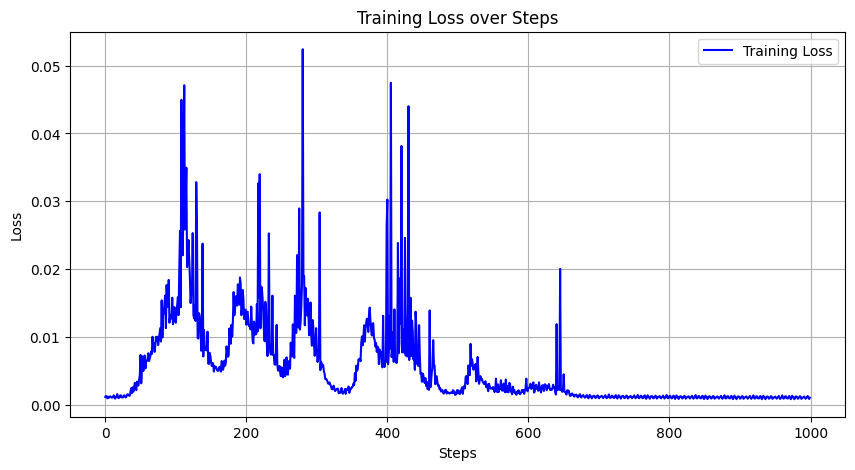


Model checkpoint saved to gpt2_124m_checkpoint.pth


In [38]:
import matplotlib.pyplot as plt

total_batch_size = 65536
B = 8
T = 1024
assert total_batch_size % (B * T) == 0
grad_accum_steps = total_batch_size // (B * T)
print(f"Target tokens/step: {total_batch_size} | Gradient accumulation steps: {grad_accum_steps}")

train_loader = DataLoaderLite(B=B, T=T)
optimizer = model.configure_optimizers(weight_decay=0.1, learning_rate=6e-4, betas=(0.9, 0.95), device_type=device_type)

train_losses = []

model.train()
for step in range(max_steps):
    t0 = time.time()
    optimizer.zero_grad()
    loss_accum = 0.0

    for micro_step in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        if device_type == 'cuda':
            with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
                logits, loss = model(x, y)
        else:
            logits, loss = model(x, y)
        loss = loss / grad_accum_steps
        loss_accum += loss.detach()
        loss.backward()

    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    if device_type == 'cuda':
        torch.cuda.synchronize()
    t1 = time.time()

    train_losses.append(loss_accum.item())

    tokens_per_sec = (B * T * grad_accum_steps) / (t1 - t0)
    if step % 20 == 0 or step == max_steps - 1:
        print(f"step {step:4d} | loss: {loss_accum.item():.4f} | lr: {lr:.2e} | norm: {norm:.4f} | dt: {(t1-t0)*1000:.1f}ms | tok/sec: {tokens_per_sec:.0f}")

# --- Visual Evaluation & Checkpointing ---
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss', color='blue')
plt.title('Training Loss over Steps')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

checkpoint_path = "gpt2_124m_checkpoint.pth"
torch.save(model.state_dict(), checkpoint_path)
print(f"\nModel checkpoint saved to {checkpoint_path}")

# Autoregressive Generation with Top-K & Temperature

In [39]:
model.eval()
enc = tiktoken.get_encoding('gpt2')
prompt = "ROMEO:\n"
tokens = enc.encode(prompt)
x = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

torch.manual_seed(42)
with torch.no_grad():
    for _ in range(100):
        logits, _ = model(x[:, -1024:])
        logits = logits[:, -1, :] / 0.8
        v, _ = torch.topk(logits, 50)
        logits[logits < v[:, [-1]]] = -float('Inf')
        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        x = torch.cat((x, next_token), dim=1)

print(enc.decode(x[0].tolist()))

ROMEO:
I never no holy to die, my lord and leaveily eyesMARIAN; it is scarce it were lost his enemies and Cor what I can serve:
You mock me see him.

ROMEO:
True, madam, your state, in this business we went no hopeful lady's good Camillo?
CUTUS:
Well,
Had answer it.
Believe it.

More liest money,
And your fate all the matter?
